### Customer Churn Prediction

In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings("ignore")

In [2]:
import os 
from pathlib import Path
data_dir = Path(r"D:\Customer Churn Prediction\data")
train_df = pd.read_csv(data_dir/"raw/customer_churn_dataset-training-master.csv")
test_df = pd.read_csv(data_dir/"raw/customer_churn_dataset-testing-master.csv")

In [3]:
train_df.dropna(how="all",inplace=True)
test_df.dropna(how="all",inplace=True)

# Combine Datasets
df=pd.concat(
    [train_df,test_df],
    axis=0,
    ignore_index=True
)

In [4]:
print("Combined Dataset shape:",df.shape)
df.head

Combined Dataset shape: (505206, 12)


<bound method NDFrame.head of         CustomerID   Age  Gender  Tenure  Usage Frequency  Support Calls  \
0              2.0  30.0  Female    39.0             14.0            5.0   
1              3.0  65.0  Female    49.0              1.0           10.0   
2              4.0  55.0  Female    14.0              4.0            6.0   
3              5.0  58.0    Male    38.0             21.0            7.0   
4              6.0  23.0    Male    32.0             20.0            5.0   
...            ...   ...     ...     ...              ...            ...   
505201     64370.0  45.0  Female    33.0             12.0            6.0   
505202     64371.0  37.0    Male     6.0              1.0            5.0   
505203     64372.0  25.0    Male    39.0             14.0            8.0   
505204     64373.0  50.0  Female    18.0             19.0            7.0   
505205     64374.0  52.0  Female    45.0             15.0            9.0   

        Payment Delay Subscription Type Contract Length  

In [5]:
print("Duplicate rows:",df.duplicated().sum())
print("Duplicate Customer IDs:",
      df["CustomerID"].duplicated().sum())

Duplicate rows: 0
Duplicate Customer IDs: 62995


In [6]:
# Save Combined Dataset

import os 
os.makedirs(data_dir/"processed",exist_ok=True)
df.to_csv(data_dir/"processed/customer_churn_combined.csv")
print("successfully")

successfully


In [7]:
df.info()

df.describe()

df.isnull().sum()

df.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 505206 entries, 0 to 505205
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  str    
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  str    
 8   Contract Length    505206 non-null  str    
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), str(3)
memory usage: 46.3 MB


np.int64(0)

In [9]:
print("Total Rows:",len(df))
print("Unique Customer IDs:",df["CustomerID"].nunique())
print("Duplicate Customer IDS:",
      df["CustomerID"].duplicated().sum())

duplicates_ids = df[df.duplicated("CustomerID",keep=False)]
display(duplicates_ids.head(10))

Total Rows: 505206
Unique Customer IDs: 442211
Duplicate Customer IDS: 62995


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0
5,8.0,51.0,Male,33.0,25.0,9.0,26.0,Premium,Annual,129.0,8.0,1.0
6,9.0,58.0,Female,49.0,12.0,3.0,16.0,Standard,Quarterly,821.0,24.0,1.0
7,10.0,55.0,Female,37.0,8.0,4.0,15.0,Premium,Annual,445.0,30.0,1.0
8,11.0,39.0,Male,12.0,5.0,7.0,4.0,Standard,Quarterly,969.0,13.0,1.0
9,12.0,64.0,Female,3.0,25.0,2.0,11.0,Standard,Quarterly,415.0,29.0,1.0


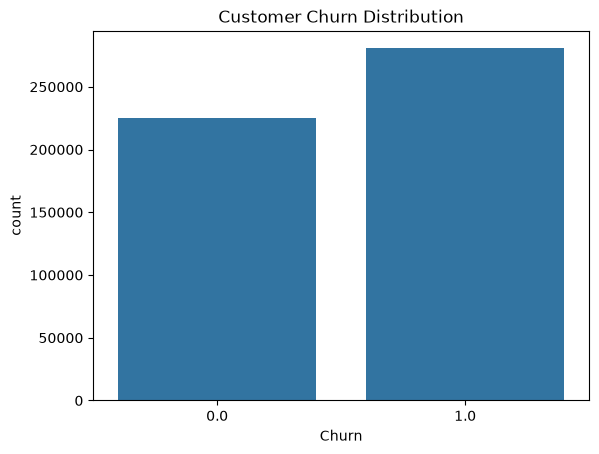

In [11]:
sns.countplot(data=df,x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

In [15]:
df["Churn"].value_counts()

Churn
1.0    280492
0.0    224714
Name: count, dtype: int64

### Correlation

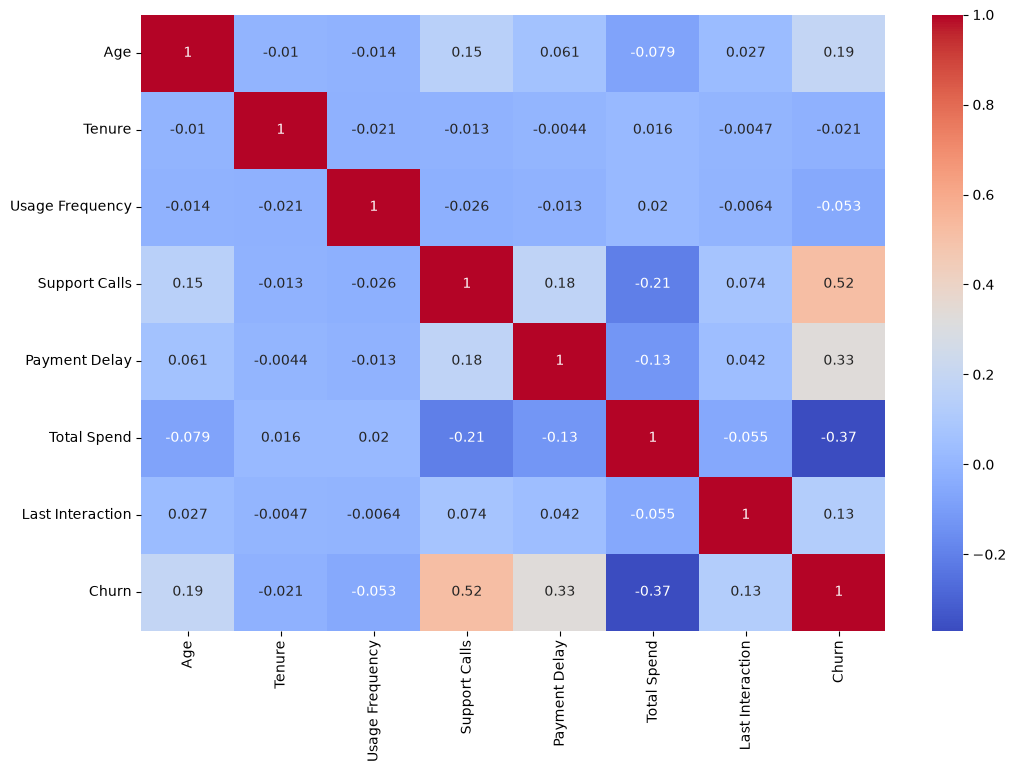

In [16]:
plt.figure(figsize=(12,8))

sns.heatmap(df.select_dtypes(include="number").drop(columns=["CustomerID"]).corr(),
            annot=True,cmap="coolwarm")
plt.show()

### Split the Combined dataset 

In [17]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["Churn","CustomerID"])
y=df["Churn"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (404164, 10)
X_test: (101042, 10)
y_train: (404164,)
y_test: (101042,)


In [18]:
import joblib

os.makedirs(data_dir/"processed",exist_ok=True)

joblib.dump((X_train,X_test,y_train,y_test),data_dir/"processed/train_test_split.pkl")

['D:\\Customer Churn Prediction\\data\\processed\\train_test_split.pkl']